## There are many ways to  create DT (Decision Tree), but we are using CART (Classification and regression Tree)

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import os
os.chdir('E:/Machine_Learning/Cases/Wisconsin/')

In [7]:
wisc = pd.read_csv("BreastCancer.csv",index_col=0)
wisc.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [8]:
X,y = wisc.drop('Class',axis = 1),wisc['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=26,test_size=0.3,stratify=y)

In [9]:
dtc = DecisionTreeClassifier(random_state=26,max_depth=2)
dtc.fit(X_train,y_train)
y_pred = dtc.predict(X_test)
accuracy_score(y_test,y_pred)


0.9333333333333333

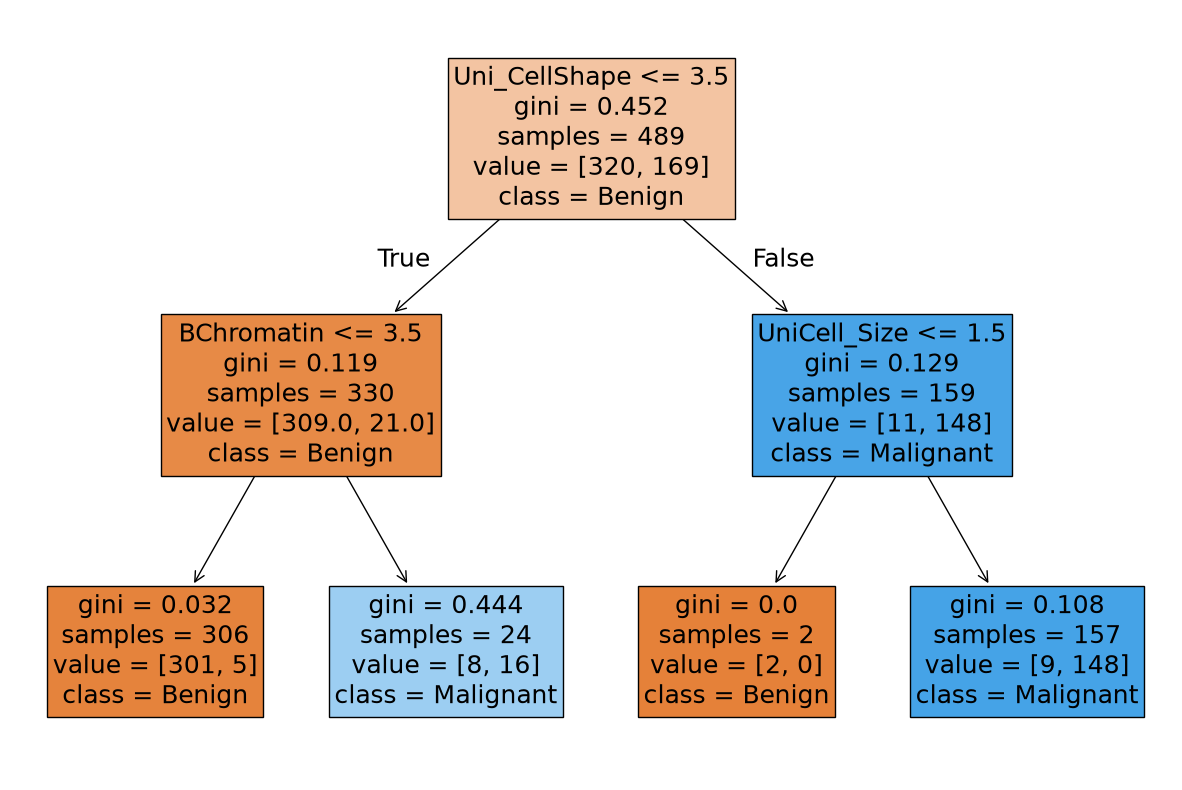

In [10]:
plt.figure(figsize = (15,10))
plot_tree(dtc,feature_names=list(X.columns),
          class_names=['Benign','Malignant'],filled=True,fontsize=18)
plt.show()

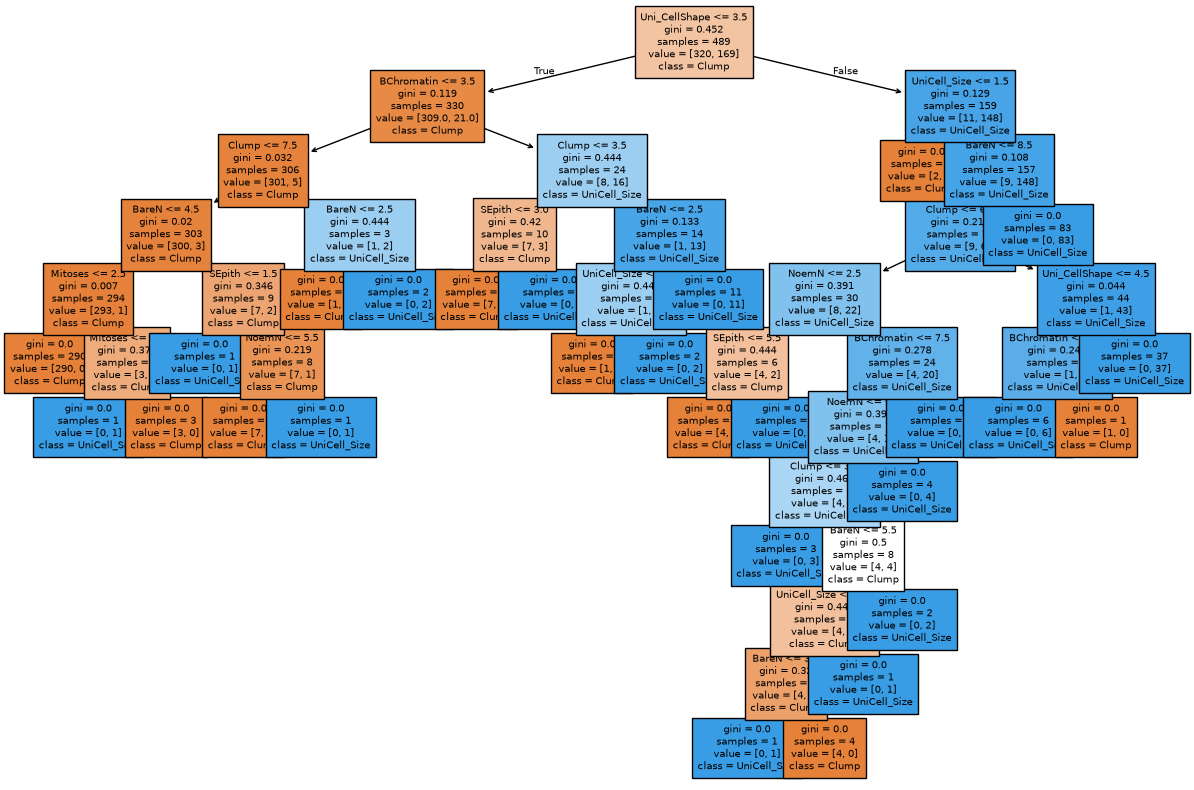

In [11]:
dtc = DecisionTreeClassifier(random_state=26,max_depth=None)
dtc.fit(X_train,y_train)
y_pred = dtc.predict(X_test)
plt.figure(figsize = (15,10))
plot_tree(dtc,feature_names=list(X.columns),class_names=list(X.columns),filled=True,fontsize=7)
plt.show()

-------
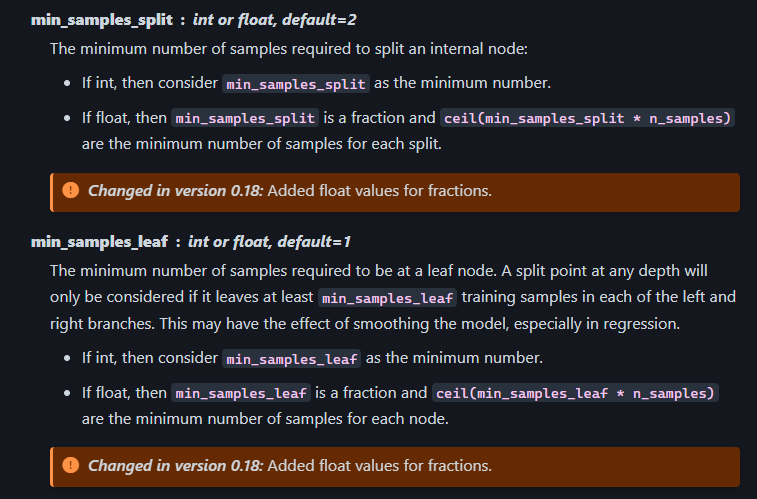

------

# min_samples_split

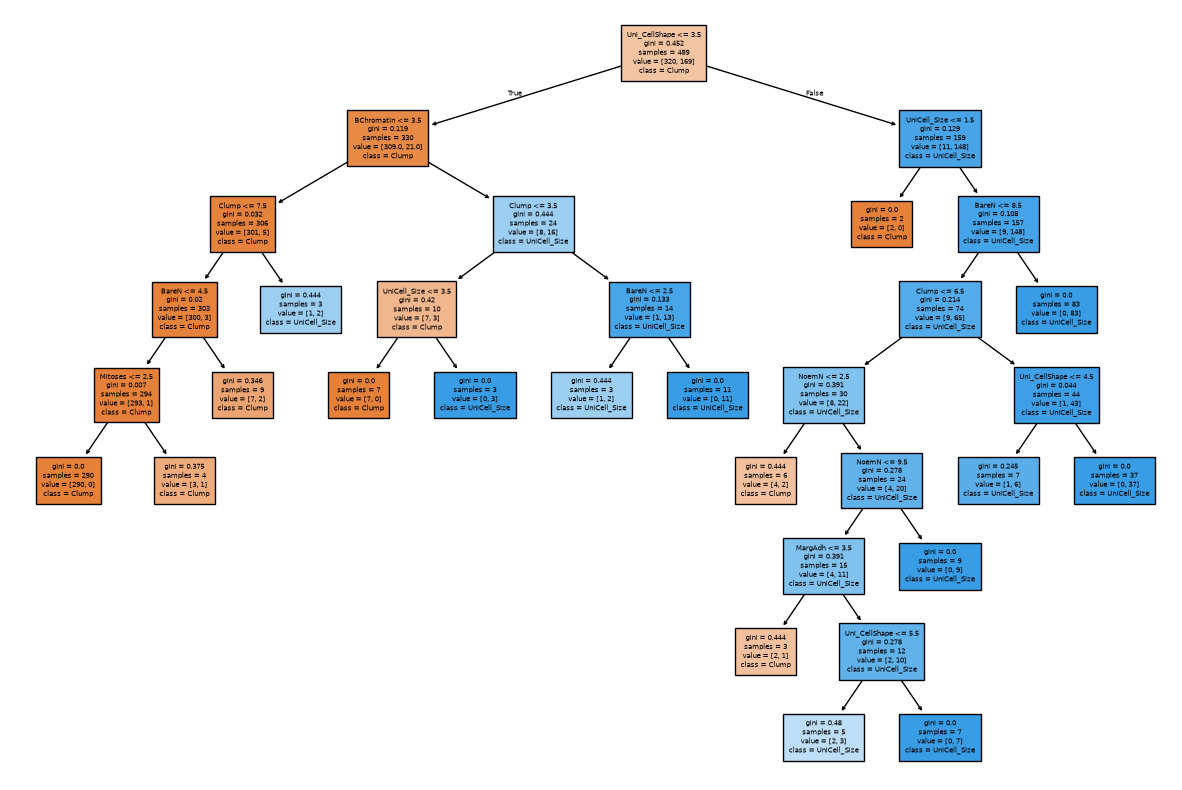

In [12]:
dtc = DecisionTreeClassifier(random_state=26,min_samples_split=10)
dtc.fit(X_train,y_train)
y_pred = dtc.predict(X_test)
plt.figure(figsize = (15,10))
plot_tree(dtc,feature_names=list(X.columns),class_names=list(X.columns),filled=True,fontsize=5)
plt.show()

# min_sample_leaf

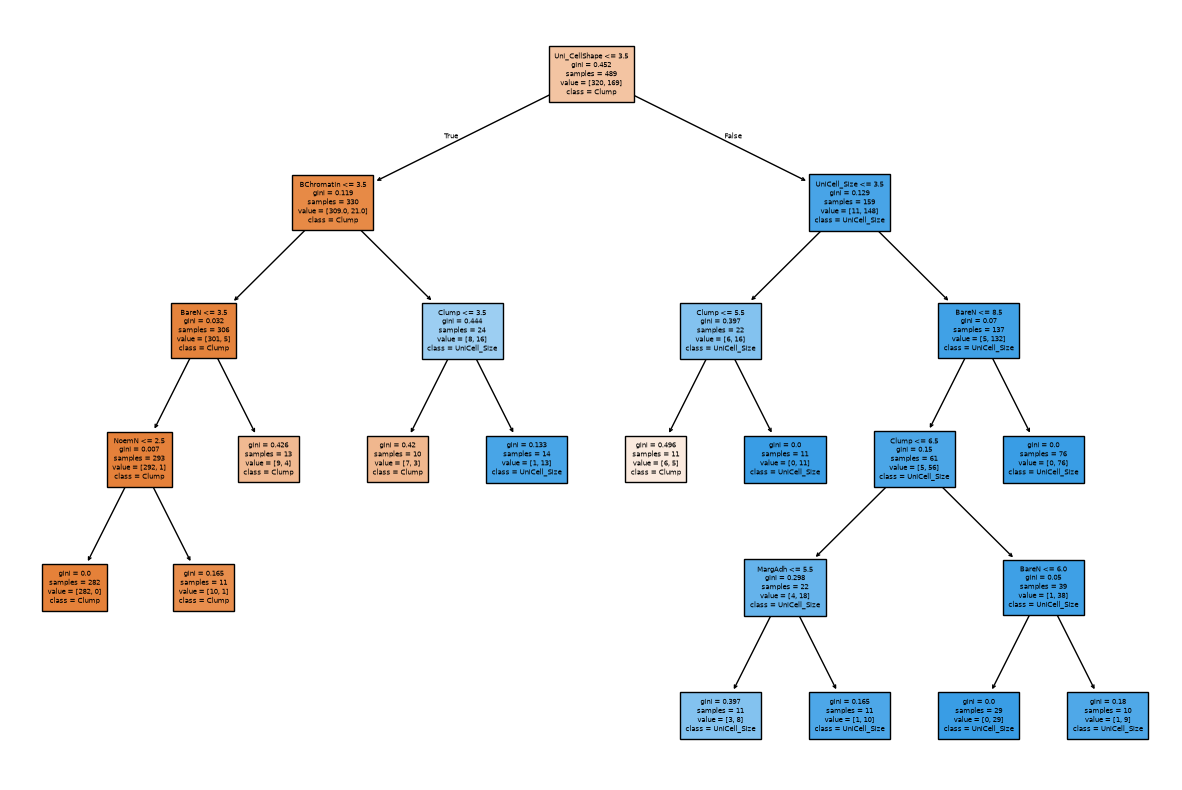

In [13]:
dtc = DecisionTreeClassifier(random_state=26,min_samples_leaf=10)
dtc.fit(X_train,y_train)
y_pred = dtc.predict(X_test)
plt.figure(figsize = (15,10))
plot_tree(dtc,feature_names=list(X.columns),class_names=list(X.columns),filled=True,fontsize=5)
plt.show()

In [14]:
depths = [None,2,3,4,5,6,7]
min_split = [2,5,10,20,50]
min_leaf = [1,5,10,20,50]
scores = []
for d in depths:
    for s in min_split:
        for f in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26,max_depth=d,min_samples_split=s,min_samples_leaf=f)
            dtc.fit(X_train,y_train)
            y_pred = dtc.predict(X_test)
            scores.append([d,s,f,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Depth','Min_sample_splits','Min_sample_leaf','Accuracy'])
df_scores.sort_values(by='Accuracy',ascending=False)

,Depth,Min_sample_splits,Min_sample_leaf,Accuracy
10,NaN,10,1,0.957143
160,7.0,10,1,0.957143
0,NaN,2,1,0.947619
125,6.0,2,1,0.947619
150,7.0,2,1,0.947619
...,...,...,...,...
149,6.0,50,50,0.895238
164,7.0,10,50,0.895238
159,7.0,5,50,0.895238
169,7.0,20,50,0.895238


## We can use floting point number for min_leaf_split it must be within range (0-1) 
## it represent percentage of original sample size

In [15]:
from sklearn.preprocessing import OneHotEncoder
from tqdm import tqdm
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector,make_column_transformer
os.chdir('E:/Machine_Learning/Cases/human-resources-analytics/')

In [16]:
df = pd.read_csv('HR_comma_sep.csv')
df.shape

(14995, 10)

In [17]:
X,y = df.drop('left',axis = 1),df['left']
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=26,test_size=0.3,stratify=y)

In [18]:
ohe = OneHotEncoder(sparse_output=False,drop='first')
ct = make_column_transformer(
    (ohe,make_column_selector(dtype_include='object')),
    remainder='passthrough',
    verbose_feature_names_out=False
)
ct = ct.set_output(transform='pandas')


In [19]:
depths = [None,2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.1,0.2,0.3]
min_leaf = [1,0.05,0.01,0.1,0.2,0.3]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26,max_depth=d,min_samples_split=s,min_samples_leaf=f)
            pipe = Pipeline([("CT",ct),('Tree',dtc)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([d,s,f,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Depth','Min_sample_splits','Min_sample_leaf','Accuracy'])
df_scores.sort_values(by='Accuracy',ascending=False)

100%|██████████| 7/7 [00:09<00:00,  1.31s/it]


,Depth,Min_sample_splits,Min_sample_leaf,Accuracy
216,7.0,2.00,1.0,0.978662
228,7.0,0.01,1.0,0.977551
6,NaN,0.05,1.0,0.977328
222,7.0,0.05,1.0,0.977328
12,NaN,0.01,1.0,0.976884
...,...,...,...,...
227,7.0,0.05,0.3,0.803734
233,7.0,0.01,0.3,0.803734
239,7.0,0.10,0.3,0.803734
245,7.0,0.20,0.3,0.803734


## SO we got the best tree which will have Depth:7, Min_sample_splits:2 , Min_sample_leaf:1 

# PLOT tree for whole data (without split)

In [20]:
best_tree = DecisionTreeClassifier(random_state=26,max_depth=7,min_samples_split=2,min_samples_leaf=1)
X_ohe = ct.fit_transform(X)
best_tree.fit(X_ohe,y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",26
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [21]:
best_tree.feature_importances_  
# This will give array of the importance of features respectively

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 4.33712854e-04,
       3.68173893e-04, 2.39615896e-04, 0.00000000e+00, 5.26663241e-01,
       1.43740513e-01, 1.08335154e-01, 6.96451857e-02, 1.50574404e-01,
       0.00000000e+00, 0.00000000e+00])

#### now we will create dataframe from this and will plot the importance for each column

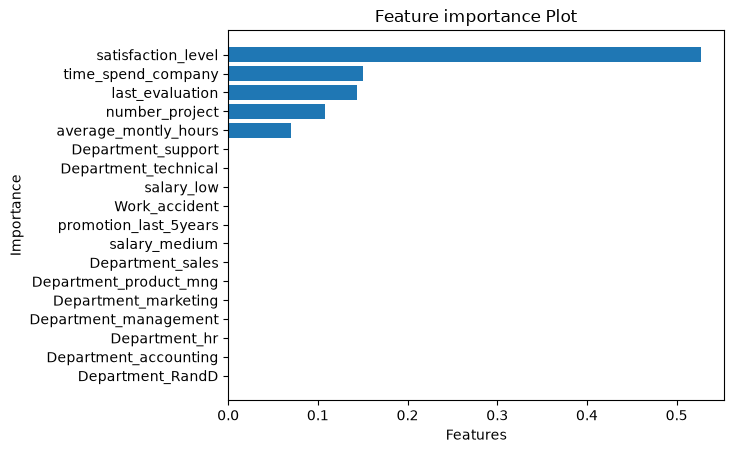

In [22]:
df_imp = pd.DataFrame(
    {'features':list(X_ohe.columns),
    'importance' : best_tree.feature_importances_}
                     )
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp['features'],df_imp['importance'])
plt.title('Feature importance Plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()